# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from the case JSON → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in the case JSON).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils import simulation as sim
from utils.config import (
    FORCING,
    SIMULATIONS,
    get_offshore_wave,
    load_goals,
    open_offshore_waves,
    open_water_level,
    open_wind,
    resolve,
    simulation_model,
)

## Configuration

In [2]:
offshore_name = "WHACS_cal"  # must match an entry in the case JSON → offshore_waves
period = "2013"  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
model = simulation_model()
templates_dir = sim.templates_dir("dynamic")
cases_dir = sim.cases_dir("dynamic")
grid_file = sim.grid_file()
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])
raw_goals = load_goals()

print(f"model     : {model}")
print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"grid      : {grid_file}")
print(f"period    : {period}")

model     : snapwave
offshore  : WHACS_cal → /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/WHACS/processed/Netherlands_WHACS_goal_cal.zarr
goals     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.json
templates : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/templates-snapwave-dynamic
cases     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Dynamic
grid      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/GRID/Netherlands_mesh.nc
period    : 2013


## Offshore waves → boundary forcing

In [3]:
offshore_ds = open_offshore_waves(entry=offshore_entry).sel(time=period).load()
offshore_ds

<xarray.Dataset> Size: 17MB
Dimensions:   (goal: 10, time: 8760)
Coordinates:
  * goal      (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    seapoint  (goal) int64 80B 2323617 2334975 2324234 ... 2326133 2326141
  * time      (time) datetime64[ns] 70kB 2013-01-01 ... 2013-12-31T23:00:00
Data variables: (12/24)
    dir       (goal, time) float64 701kB 234.3 235.3 237.0 ... 205.5 209.6 214.2
    hs        (goal, time) float64 701kB 1.853 1.705 1.642 ... 1.335 1.301 1.267
    pdir0     (goal, time) float64 701kB 234.3 235.2 236.9 ... 169.3 171.0 173.2
    pdir1     (goal, time) float64 701kB nan 354.0 354.2 ... 257.5 258.1 258.3
    pdir2     (goal, time) float64 701kB nan nan nan nan ... 309.9 311.1 324.9
    pdir3     (goal, time) float64 701kB nan nan nan nan ... 337.0 336.3 332.2
    ...        ...
    ptp0      (goal, time) float64 701kB 6.78 6.82 5.39 5.17 ... 4.25 4.27 4.23
    ptp1      (goal, time) float64 701kB nan 14.62 14.47 ... 7.52 7.39 7.49
    ptp2      (goal, time) float64 701kB nan nan nan nan ... 8.12 7.96 7.73 8.0
    ptp3      (goal, time) float64 701kB nan nan nan nan ... 10.22 9.71 15.74
    spr       (goal, time) float64 701kB 23.0 23.0 23.5 24.7 ... 58.7 58.5 58.0
    tp        (goal, time) float64 701kB 6.803 6.803 5.376 ... 4.274 4.31 7.692
Attributes: (12/60)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S
    hywaves_calibration:             {"source": "WHACS", "reference": "IMOS a...

In [4]:
# One case per time step: per-goal (= boundary node) hs/tp/dir/spr lists + tref,
# and wl from forcing.water_level (CODEC; 0 where it has no value, after 2018)
metamodel_parameters = sim.dynamic_parameters(
    offshore_ds, water_level="water_level" in FORCING
)
list(metamodel_parameters.keys())

['hs_nodes', 'tp_nodes', 'dir_nodes', 'spr_nodes', 'wl_nodes', 'tref']

In [ ]:
import numpy as np

# Grid maps (save_map) for some time steps. With map_reference (the dynamic
# cases folder of another run, e.g. the other model), the same hours get a map,
# so the two can be compared map by map; otherwise a random 5 %.
map_reference = resolve("portal_snapwave/SnapWave_CASES_Dynamic")
n_cases = len(metamodel_parameters["tref"])
if map_reference is not None and map_reference.is_dir():
    map_trefs = {p.parent.name for p in map_reference.glob("*/output_map.*")}
    metamodel_parameters["save_map"] = [
        tref in map_trefs for tref in metamodel_parameters["tref"]
    ]
else:
    metamodel_parameters["save_map"] = np.random.choice(
        [True, False], size=n_cases, p=[0.1, 0.9]
    ).tolist()
sum(metamodel_parameters["save_map"]), n_cases

(391, 8760)

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + observed direction-range bars per goal; right side = text summary.
Each case is one timestep with **all goals forced** on the boundary.
Review this before `build_cases()`.

In [6]:
# Case geometry: goals = boundary nodes, AoI enclosure, labelled output sites
setup = sim.HyWavesWrapperSetup.from_case(raw_goals)

# Wind field (forcing.wind, ERA5) at each case time; None runs without wind
wind = (
    open_wind(slice(offshore_ds.time.values[0], offshore_ds.time.values[-1]))
    if "wind" in FORCING
    else None
)
wrapper = setup.dynamic_wrapper(metamodel_parameters, wind=wind)
wrapper

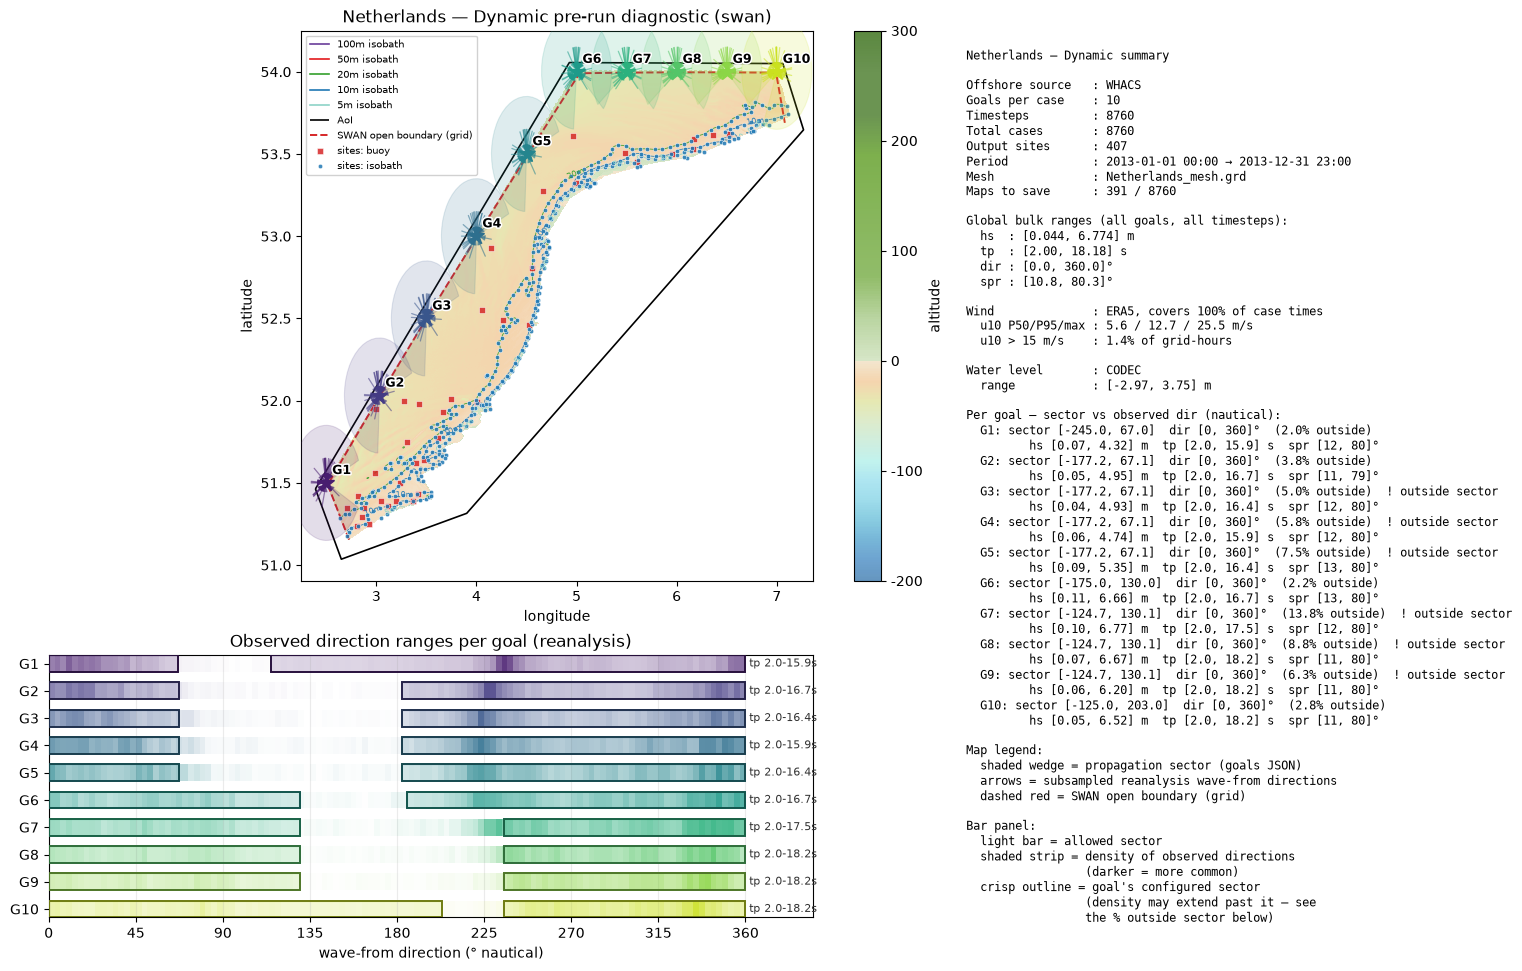

In [7]:
# Water level (forcing.water_level) at the goals, as given to the cases
water_level = open_water_level() if "water_level" in FORCING else None

fig = setup.plot_dynamic_configuration(
    offshore_ds,
    offshore_name=offshore_name,
    save_map=metamodel_parameters.get("save_map"),
    wind=wind,
    water_level=water_level,
)
# fig.savefig("dynamic_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
# On the GeoOcean cluster: one SLURM array task per case. Writes case_dirs.txt
# and the array script into the cases folder (options from
# simulations.<model>.slurm), then submits it with sbatch.
# wrapper.run_cases_slurm(**sim.slurm_kwargs(max_parallel=96))

In [10]:
# Or a few cases interactively ("geoocean-cluster" loads the snapwave module):
# wrapper.run_cases_in_background(
#     launcher="geoocean-cluster",
#     num_workers=3,
#     cases_to_run=[144, 454, 16100],
# )

In [15]:
wrapper.monitor_cases(value_counts="simple")

Status     
NOT STARTED    5184
FINISHED       3481
RUNNING          95
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map when `save_map=True` for that timestep
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


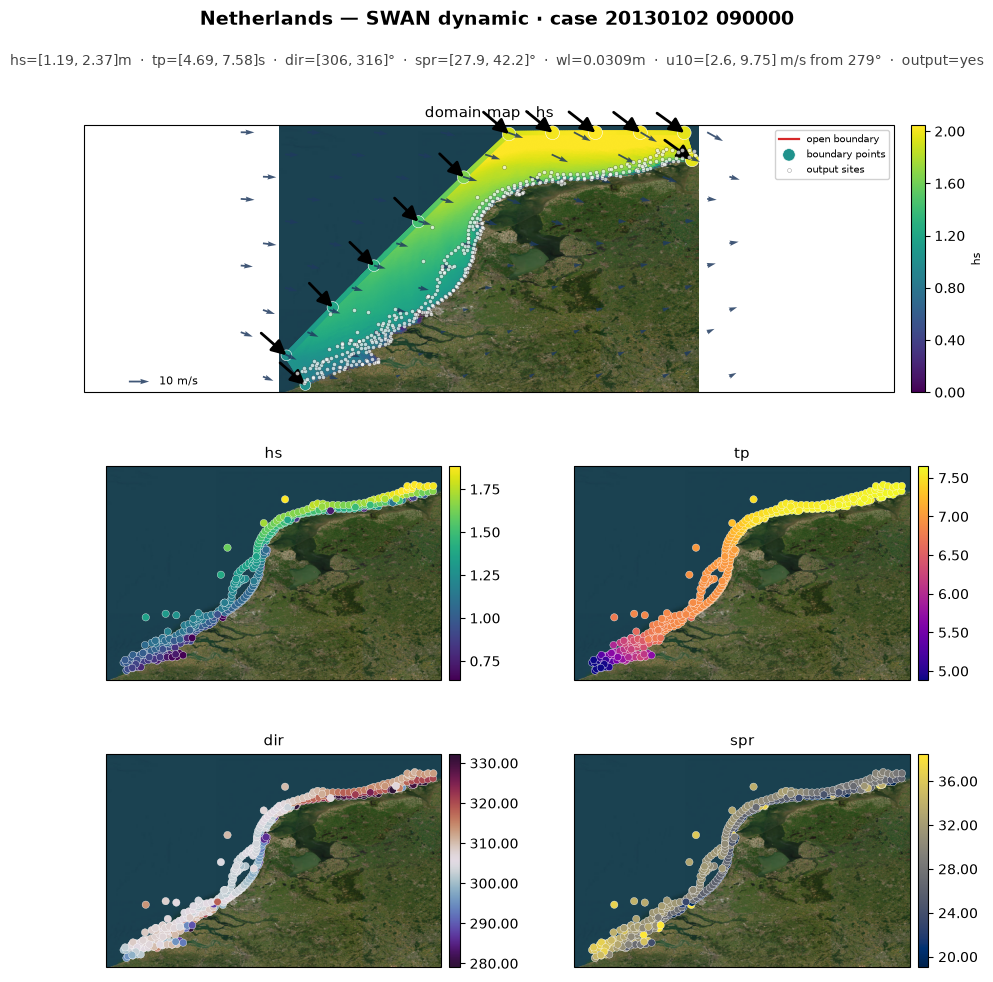

In [17]:
from bluemath_tk.core.plotting.cases import CasePlotStyle
from utils.viz import plot_dynamic_case

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
# First time step with a grid map
first_map = next(
    tref
    for tref, save in zip(
        metamodel_parameters["tref"], metamodel_parameters["save_map"]
    )
    if save
)
plot_dynamic_case(cases_dir / first_map, style=style, show_satellite=True);

In [13]:
result = wrapper.postprocess_cases(cases_to_postprocess=range(3096))
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_2013_0101_0509.nc"
result.to_netcdf(out_nc)

In [14]:
import xarray as xr

xr.open_dataset(out_nc).load().nbytes * 1e-9  # GB

0.040425216